# V0.1 deterministic video ingestion

This executed notebook generates tiny constant- and variable-frame-rate videos, ingests them with PyAV, stores the existing `VideoAsset` and `Frame` contracts, and displays threshold-free capture diagnostics. If an existing local benchmark golf video is present, it is read in place and is never copied into Git. No pose inference is performed.

In [1]:
import tempfile
from datetime import date
from fractions import Fraction
from pathlib import Path

import av
import numpy as np
from IPython.display import Image, display

from open_swing_analysis.contracts import CameraView, Handedness, Swing, SwingSession
from open_swing_analysis.ingestion import (
    FrameSelection, VideoReader, ingest_video, store_ingestion_result, write_contact_sheet
)
from open_swing_analysis.storage import LocalDataStore

temporary_directory = tempfile.TemporaryDirectory(prefix="open-swing-ingestion-")
work = Path(temporary_directory.name)
print("Working directory:", work)
print("PyAV version:", av.__version__)

Working directory: /tmp/open-swing-ingestion-4yim5jfj
PyAV version: 16.1.0


## Generate controlled CFR and VFR fixtures

The videos contain only synthetic colour patterns. Their explicit presentation timestamps allow the ingestion output to be checked without committing media files.

In [2]:
def make_video(path: Path, timestamps_ms: list[int], width: int = 160, height: int = 96) -> Path:
    with av.open(path, mode="w") as container:
        stream = container.add_stream("libx264", rate=25)
        stream.width, stream.height = width, height
        stream.pix_fmt = "yuv420p"
        stream.time_base = Fraction(1, 1000)
        for index, timestamp_ms in enumerate(timestamps_ms):
            image = np.zeros((height, width, 3), dtype=np.uint8)
            image[..., 0] = 20 + index * 18
            image[:, 10 + index * 5 : 40 + index * 5, 1] = 220
            image[15:35, :, 2] = 40 + index * 12
            frame = av.VideoFrame.from_ndarray(image, format="rgb24")
            frame.pts = timestamp_ms
            frame.time_base = Fraction(1, 1000)
            for packet in stream.encode(frame):
                container.mux(packet)
        for packet in stream.encode():
            container.mux(packet)
    return path

cfr_path = make_video(work / "synthetic_cfr.mp4", list(range(0, 480, 40)))
vfr_path = make_video(work / "synthetic_vfr.mov", [0, 40, 120, 160, 240, 280, 400, 440])
cfr = ingest_video(cfr_path, swing_id="swing-ingestion-cfr", source_metadata={"fixture": "synthetic CFR"})
vfr = ingest_video(vfr_path, swing_id="swing-ingestion-vfr", source_metadata={"fixture": "synthetic VFR"})

for label, result in (("CFR", cfr), ("VFR", vfr)):
    print(label, {
        "frames": result.asset.frame_count,
        "mode": result.asset.frame_rate_mode.value,
        "nominal_fps": result.asset.nominal_fps,
        "observed_fps": result.summary.observed_fps,
        "timestamps": [round(frame.timestamp_s, 3) for frame in result.frames],
        "sha256_prefix": result.asset.sha256[:16],
    })

CFR {'frames': 12, 'mode': 'constant', 'nominal_fps': 25.0, 'observed_fps': 25.0, 'timestamps': [0.0, 0.04, 0.08, 0.12, 0.16, 0.2, 0.24, 0.28, 0.32, 0.36, 0.4, 0.44], 'sha256_prefix': '1282466c11772fef'}
VFR {'frames': 8, 'mode': 'variable', 'nominal_fps': 25.0, 'observed_fps': 15.909090909090908, 'timestamps': [0.0, 0.04, 0.12, 0.16, 0.24, 0.28, 0.4, 0.44], 'sha256_prefix': 'a23fe980dd9ee2cb'}


## Store JSON, Parquet, summaries and plots

The existing session/swing store writes canonical `frames.parquet`. Raw PTS, timestamp source, dimensions, and numerical quality diagnostics are stored in the versioned capture-quality sidecar.

In [3]:
store = LocalDataStore(work / "store")
session = SwingSession(
    session_id="session-video-ingestion",
    subject_id="subject-synthetic",
    recording_date=date(2026, 11, 3),
    camera_view=CameraView.UNKNOWN,
    golfer_handedness=Handedness.UNKNOWN,
    capture_metadata={"notebook": "02_video_ingestion"},
)
store.write_session(session)

def persist(result, swing_id: str):
    store.write_video_asset(session.session_id, result.asset)
    swing = Swing(
        swing_id=swing_id, session_id=session.session_id,
        video_asset_id=result.asset.asset_id, club_type="unknown"
    )
    store.write_swing(swing)
    return store_ingestion_result(store, session.session_id, swing_id, result)

cfr_outputs = persist(cfr, "swing-ingestion-cfr")
vfr_outputs = persist(vfr, "swing-ingestion-vfr")
print("CFR asset JSON:", cfr_outputs.asset_json.relative_to(store.root))
print("CFR frames:", cfr_outputs.frames_parquet.relative_to(store.root))
print("CFR diagnostics:", cfr_outputs.diagnostics_parquet.relative_to(store.root))
print("VFR timestamp intervals:", [
    round(row.inter_frame_delta_s, 3) if row.inter_frame_delta_s is not None else None
    for row in vfr.diagnostics
])

CFR asset JSON: sessions/session-video-ingestion/assets/asset-1282466c11772fef.json
CFR frames: sessions/session-video-ingestion/swings/swing-ingestion-cfr/frames.parquet
CFR diagnostics: sessions/session-video-ingestion/swings/swing-ingestion-cfr/diagnostics/capture_quality.parquet
VFR timestamp intervals: [None, 0.04, 0.08, 0.04, 0.08, 0.04, 0.12, 0.04]


CFR capture summary
{
  "schema_version": "0.1.0",
  "asset_id": "asset-1282466c11772fef",
  "total_decoded_frames": 12,
  "selected_frames": 12,
  "declared_frames": 12,
  "declared_frame_shortfall": 0,
  "decode_error_count": 0,
  "decode_errors": [],
  "missing_timestamp_count": 0,
  "duplicate_timestamp_count": 0,
  "non_monotonic_timestamp_count": 0,
  "negative_timestamp_count": 0,
  "irregular_interval_count": 0,
  "median_inter_frame_s": 0.04,
  "max_timestamp_deviation_s": 3.469446951953614e-17,
  "observed_fps": 25.0,
  "nominal_fps": 25.0,
  "frame_rate_mode": "constant",
  "mean_brightness": 62.23018663194444,
  "mean_contrast": 50.58265524655665,
  "mean_blur_laplacian_variance": 374.14645588969074,
  "encoded_width_px": 160,
  "encoded_height_px": 96,
  "display_width_px": 160,
  "display_height_px": 96,
  "rotation_degrees": 0
}


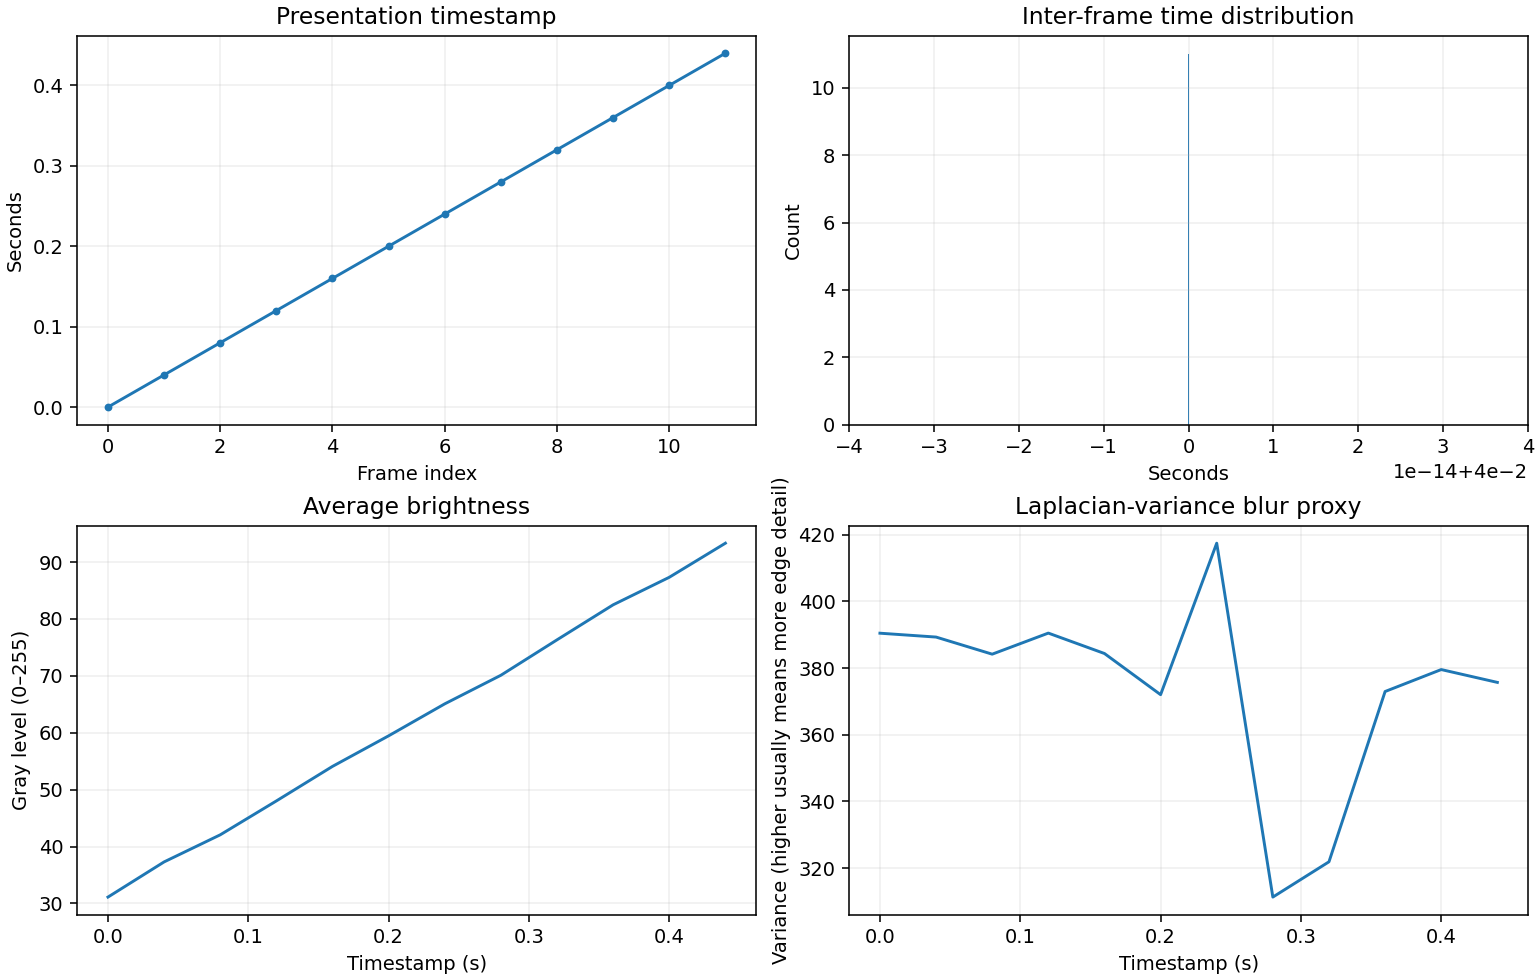

VFR capture summary
{
  "schema_version": "0.1.0",
  "asset_id": "asset-a23fe980dd9ee2cb",
  "total_decoded_frames": 8,
  "selected_frames": 8,
  "declared_frames": 8,
  "declared_frame_shortfall": 0,
  "decode_error_count": 0,
  "decode_errors": [],
  "missing_timestamp_count": 0,
  "duplicate_timestamp_count": 0,
  "non_monotonic_timestamp_count": 0,
  "negative_timestamp_count": 0,
  "irregular_interval_count": 3,
  "median_inter_frame_s": 0.040000000000000036,
  "max_timestamp_deviation_s": 0.07999999999999996,
  "observed_fps": 15.909090909090908,
  "nominal_fps": 25.0,
  "frame_rate_mode": "variable",
  "mean_brightness": 50.9205078125,
  "mean_contrast": 50.61202654193189,
  "mean_blur_laplacian_variance": 404.4766866415298,
  "encoded_width_px": 160,
  "encoded_height_px": 96,
  "display_width_px": 160,
  "display_height_px": 96,
  "rotation_degrees": 0
}


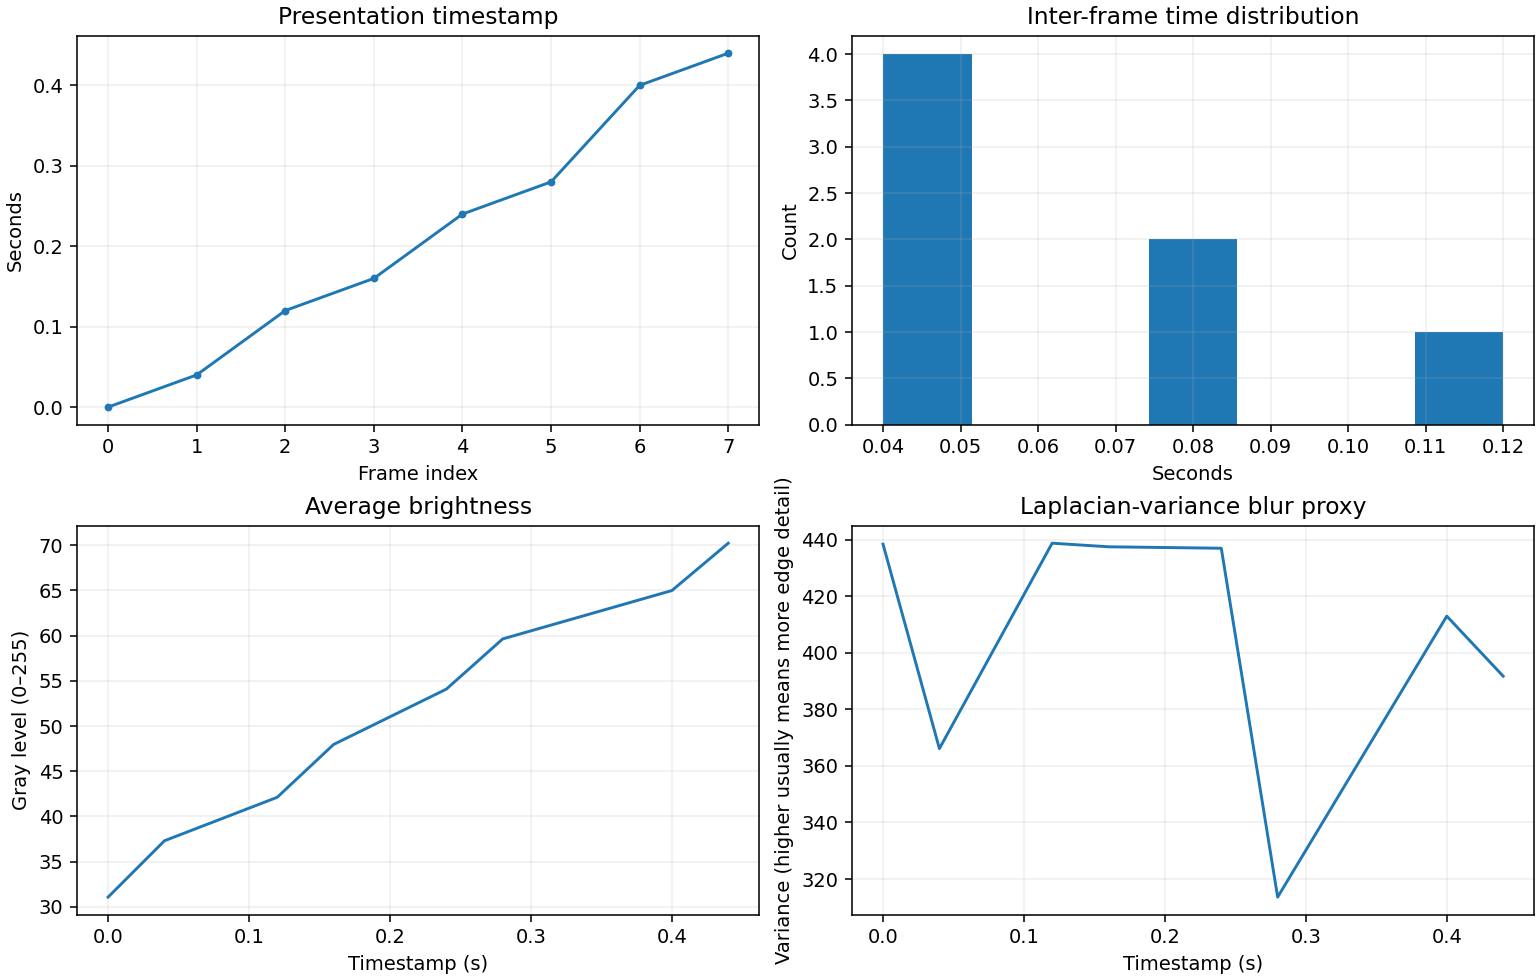

In [4]:
print("CFR capture summary")
print(cfr.summary.model_dump_json(indent=2))
display(Image(filename=str(cfr_outputs.plots_png)))
print("VFR capture summary")
print(vfr.summary.model_dump_json(indent=2))
display(Image(filename=str(vfr_outputs.plots_png)))

## Representative frames

Only explicitly selected display-oriented frames are retained for these contact sheets.

CFR [(0, 0.0), (3, 0.12), (6, 0.24), (9, 0.36)]


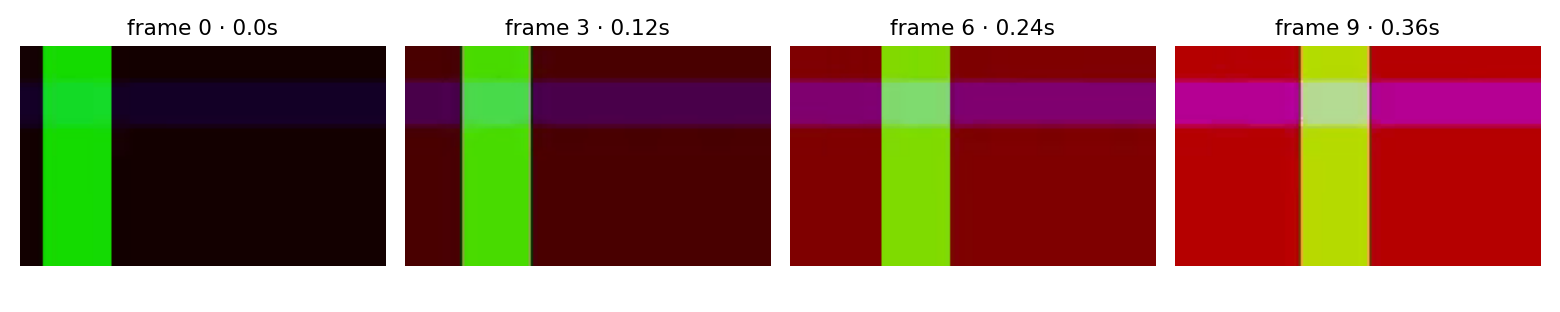

VFR [(0, 0.0), (2, 0.12), (4, 0.24), (7, 0.44)]


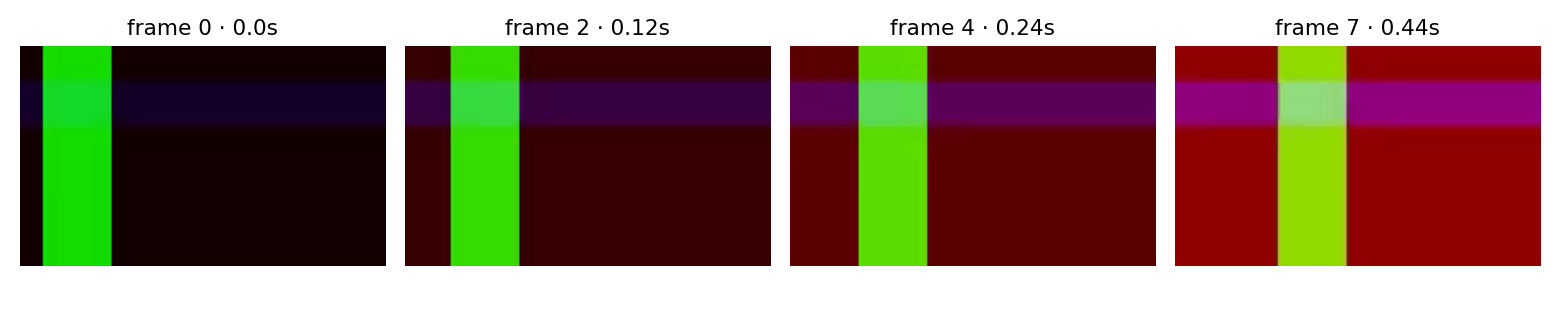

In [5]:
for label, video_path, indexes in (
    ("CFR", cfr_path, frozenset({0, 3, 6, 9})),
    ("VFR", vfr_path, frozenset({0, 2, 4, 7})),
):
    representative = list(VideoReader(video_path).iter_frames(FrameSelection(indices=indexes)))
    contact_path = write_contact_sheet(representative, work / f"{label.lower()}_contact.png")
    print(label, [(frame.frame_index, frame.original_timestamp_s) for frame in representative])
    display(Image(filename=str(contact_path)))

## Existing local golf video, when available

The benchmark video is read from its existing local path. It is not copied into the repository or the temporary store. Runtime is reported separately from deterministic persisted metadata.

Source: /tmp/golf-benchmark-repos/heleena-golf-swing-analysis/input/Reference_Swing_DTL.mp4
Asset: {
  "schema_version": "0.1.0",
  "asset_id": "asset-aacdfe30233ba524",
  "source_filename": "Reference_Swing_DTL.mp4",
  "source_path": "/tmp/golf-benchmark-repos/heleena-golf-swing-analysis/input/Reference_Swing_DTL.mp4",
  "sha256": "aacdfe30233ba524618baa6e685bb9862cd6388ff3a95d0644089a4bb418b954",
  "width_px": 734,
  "height_px": 1080,
  "nominal_fps": 30.0,
  "frame_rate_mode": "constant",
  "duration_s": 15.5,
  "frame_count": 465,
  "codec": "h264",
  "acquisition_metadata": {
    "ingestion_backend": "PyAV",
    "ingestion_backend_version": "16.1.0",
    "container_format": "mov,mp4,m4a,3gp,3g2,mj2",
    "container_format_long_name": "QuickTime / MOV",
    "stream_index": 0,
    "stream_time_base": "1/600",
    "stream_average_rate": "30",
    "stream_base_rate": "30",
    "declared_frame_count": 465,
    "decoded_frame_count": 465,
    "observed_fps": 30.0,
    "median_inter_fra

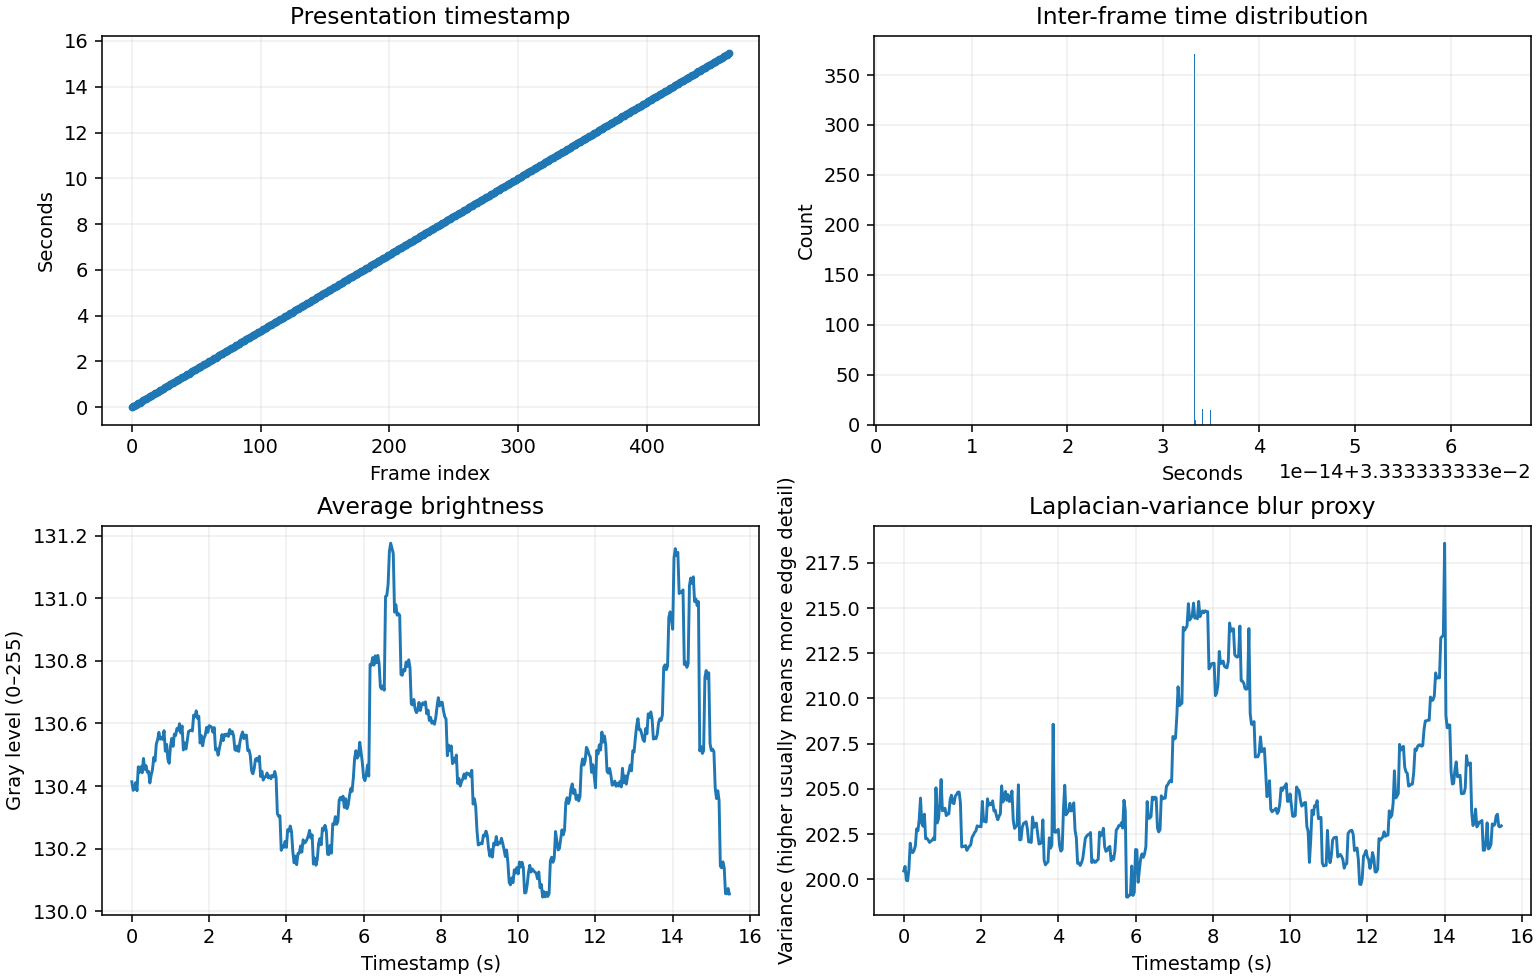

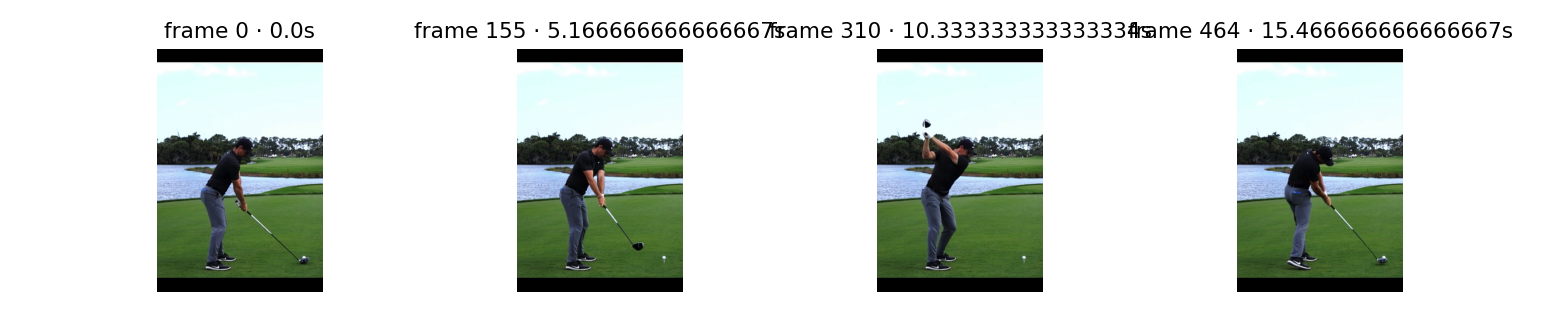

In [6]:
real_candidates = [
    Path("/tmp/golf-benchmark-repos/heleena-golf-swing-analysis/input/Reference_Swing_DTL.mp4"),
    Path("/tmp/golf-benchmark-repos/greggjuri-golf-swing-analyzer/tests/test_data/test_swing.mp4"),
]
real_path = next((path for path in real_candidates if path.exists()), None)
if real_path is None:
    print("No existing local golf sample was available; synthetic demonstrations completed.")
else:
    real = ingest_video(
        real_path, swing_id="swing-ingestion-real",
        source_metadata={"source": "existing local benchmark; not copied"},
    )
    real_outputs = persist(real, "swing-ingestion-real")
    print("Source:", real_path)
    print("Asset:", real.asset.model_dump_json(indent=2))
    print("Summary:", real.summary.model_dump_json(indent=2))
    print("Performance:", {
        "elapsed_decode_s": round(real.performance.elapsed_decode_s, 3),
        "decoded_frames_per_s": round(real.performance.decoded_frames_per_s or 0, 1),
    })
    display(Image(filename=str(real_outputs.plots_png)))
    count = real.asset.frame_count
    indexes = frozenset({0, count // 3, (2 * count) // 3, count - 1})
    representative = list(VideoReader(real_path).iter_frames(FrameSelection(indices=indexes)))
    real_contact = write_contact_sheet(representative, work / "real_contact.png")
    display(Image(filename=str(real_contact)))

In [7]:
print("EXECUTED_OK")

EXECUTED_OK
